## Earlier GARCH notebook

Working copy that precedes `VaR_Forecasting_GARCH.ipynb`. The reported comparison (45 delta-normal violations, AE 3.75, versus 13 GARCH violations, AE near 1) is computed in the later notebook. See `GARCH.md`. This file uses a ₹1 crore book and a 501-day slice, closer to the historical-simulation setup than to the 1,000-unit GARCH exercise.


In [42]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\GARCH


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

In [44]:
nifty_df = pd.read_excel(NIFTY_PATH)  # data/Nifty50_data.xlsx


In [45]:
initial_investment = 10000000 # Initial investment amount
shares_held = initial_investment/nifty_df['NIFTY Index'].iloc[0] # Number of shares purchased
# Calculate the portfolio value based on the number of shares held
nifty_df['Portfolio Value'] = shares_held * nifty_df['NIFTY Index']

In [46]:
nifty_df.head()

,Dates,EIM IS Equity,AXSB IS Equity,BJFIN IS Equity,SBILIFE IS Equity,RELIANCE IS Equity,ITC IS Equity,MM IS Equity,SBIN IS Equity,HNDL IS Equity,...,DIVI IS Equity,UTCEM IS Equity,UPLL IS Equity,TECHM IS Equity,BJAUT IS Equity,BRIT IS Equity,GRASIM IS Equity,TATACONS IS Equity,NIFTY Index,Portfolio Value
0,2005-01-04,26.63,37.94,NaN,NaN,60.51,29.21,69.22,61.31,121.39,...,66.20,343.10,50.00,NaN,NaN,93.07,166.90,50.00,2103.75,1.000000e+07
1,2005-01-05,25.70,36.85,NaN,NaN,60.36,28.82,67.58,58.25,116.54,...,63.93,333.50,49.25,NaN,NaN,90.51,162.11,48.61,2032.20,9.659893e+06
2,2005-01-06,25.16,37.03,NaN,NaN,59.93,28.37,66.41,57.01,113.20,...,62.05,338.25,47.91,NaN,NaN,90.12,161.31,48.14,1998.35,9.498990e+06
3,2005-01-07,25.40,38.02,NaN,NaN,61.76,28.89,65.96,58.08,113.11,...,62.17,333.65,47.93,NaN,NaN,90.13,161.22,49.35,2015.50,9.580511e+06
4,2005-01-10,25.47,38.42,NaN,NaN,60.84,28.32,64.75,56.60,111.10,...,64.53,339.70,49.14,NaN,NaN,90.22,158.06,49.47,1982.00,9.421272e+06


In [47]:
nf_train = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[0:501]
nf_train.head()

,Dates,NIFTY Index,Portfolio Value
0,2005-01-04,2103.75,1.000000e+07
1,2005-01-05,2032.20,9.659893e+06
2,2005-01-06,1998.35,9.498990e+06
3,2005-01-07,2015.50,9.580511e+06
4,2005-01-10,1982.00,9.421272e+06


In [48]:
nf_train['Log Returns']=np.log(nf_train['NIFTY Index']/nf_train['NIFTY Index'].shift(1))
log_returns=(np.log(nf_train['NIFTY Index']/nf_train['NIFTY Index'].shift(1))).dropna()
scaled_log_returns = log_returns * 100
print(log_returns)

1     -0.034603
2     -0.016797
3      0.008545
4     -0.016761
5     -0.015226
         ...   
496    0.001643
497    0.006673
498    0.010840
499    0.000850
500    0.003680
Name: NIFTY Index, Length: 500, dtype: float64


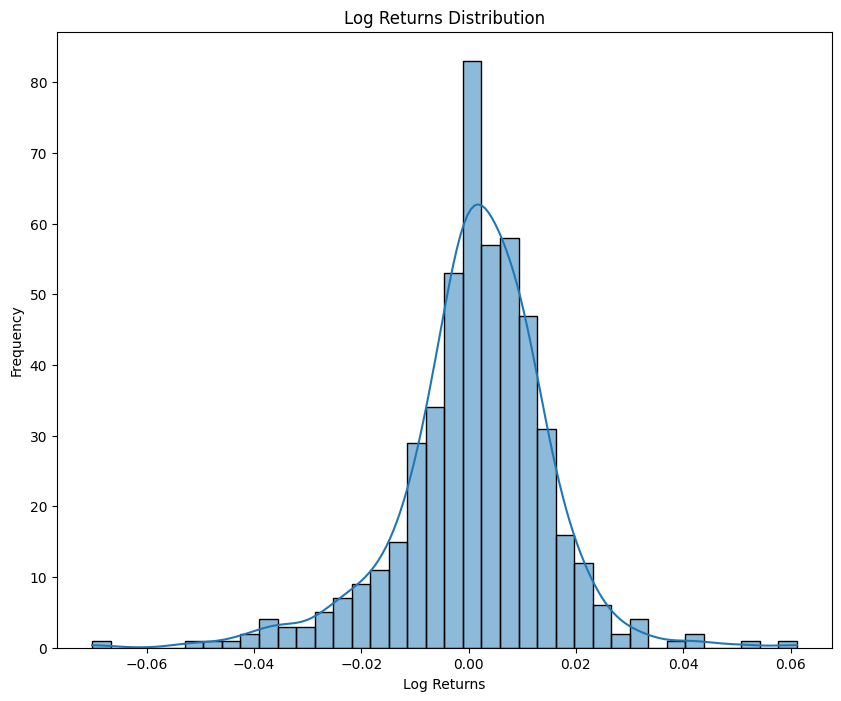

In [49]:
plt.figure(figsize=(10,8))
sns.histplot(log_returns, kde=True)
plt.title('Log Returns Distribution')
plt.xlabel('Log Returns')
plt.ylabel('Frequency')
plt.show()

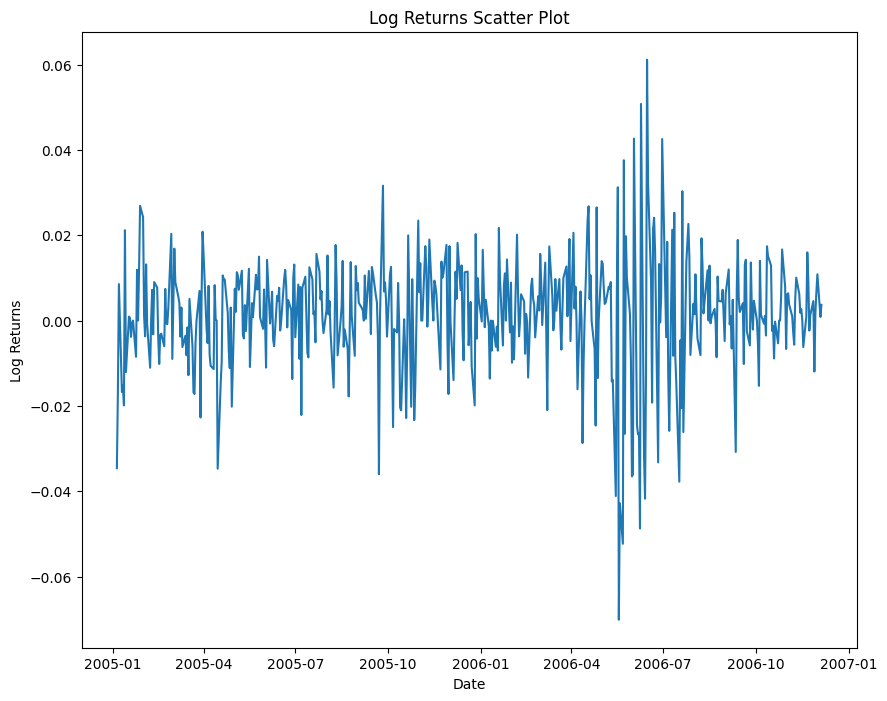

In [50]:
plt.figure(figsize=(10,8))
plt.plot(nf_train['Dates'][1:], log_returns)
plt.title('Log Returns Scatter Plot')
plt.xlabel('Date')
plt.ylabel('Log Returns')
plt.show()

In [51]:
import plotly.express as px
fig = px.line(nf_train, x="Dates", y="Log Returns", title='Life expectancy in Canada')
fig.show()

In [52]:
nf_train['scaled_log_returns'] = nf_train['Log Returns']*100

In [53]:
from arch import arch_model
model = arch_model(scaled_log_returns, vol='Garch', p=1, q=1)
fitted_model = model.fit()
fitted_model.summary()
conditional_volatility = fitted_model.conditional_volatility

Iteration:      1,   Func. Count:      6,   Neg. LLF: 15394.403629286537
Iteration:      2,   Func. Count:     15,   Neg. LLF: 44102664355.93822
Iteration:      3,   Func. Count:     23,   Neg. LLF: 933.1289882918082
Iteration:      4,   Func. Count:     30,   Neg. LLF: 845.3721720572357
Iteration:      5,   Func. Count:     37,   Neg. LLF: 788.0193063383479
Iteration:      6,   Func. Count:     43,   Neg. LLF: 787.018454223886
Iteration:      7,   Func. Count:     48,   Neg. LLF: 787.0069662582499
Iteration:      8,   Func. Count:     53,   Neg. LLF: 787.0061846304766
Iteration:      9,   Func. Count:     58,   Neg. LLF: 787.0061154412225
Iteration:     10,   Func. Count:     63,   Neg. LLF: 787.0061070287152
Iteration:     11,   Func. Count:     67,   Neg. LLF: 787.0061070285662
Optimization terminated successfully    (Exit mode 0)
            Current function value: 787.0061070287152
            Iterations: 11
            Function evaluations: 67
            Gradient evaluations: 11

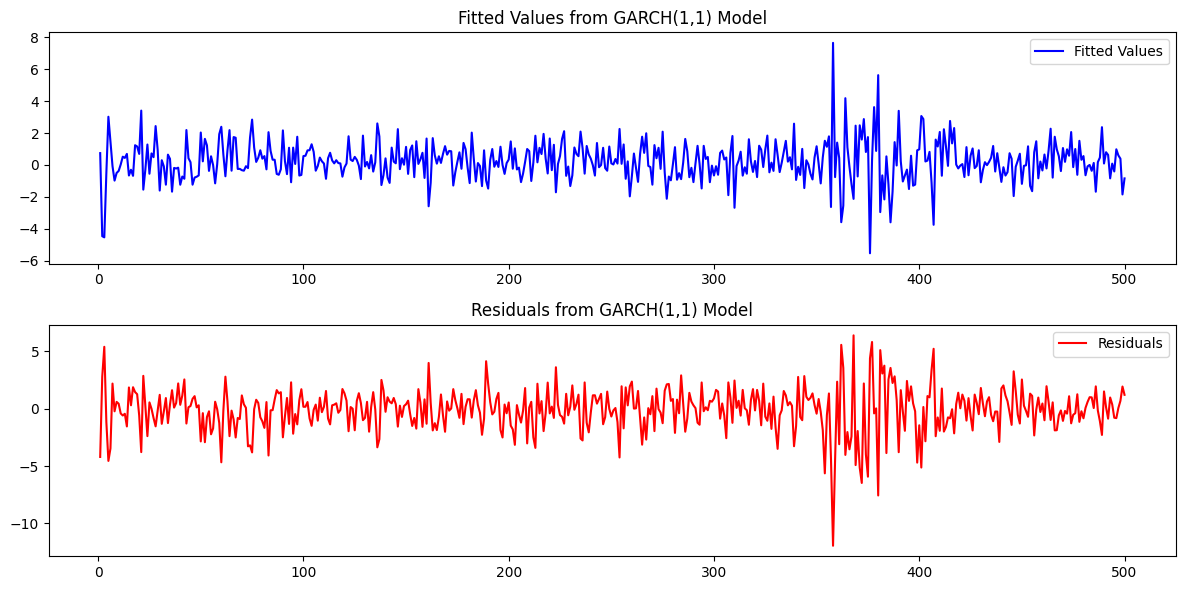

In [54]:
# 1. Plot the fitted values and residuals of the GARCH(1,1) model
fitted_values = fitted_model.params['mu'] + fitted_model.conditional_volatility * np.random.randn(len(conditional_volatility))
residuals = scaled_log_returns - fitted_values

plt.figure(figsize=(12, 6))

# Plot fitted values
plt.subplot(2, 1, 1)
plt.plot(fitted_values, label='Fitted Values', color='blue')
plt.title('Fitted Values from GARCH(1,1) Model')
plt.legend()

# Plot residuals
plt.subplot(2, 1, 2)
plt.plot(residuals, label='Residuals', color='red')
plt.title('Residuals from GARCH(1,1) Model')
plt.legend()

plt.tight_layout()
plt.show()

In [55]:
conditional_std_dev = np.sqrt(conditional_volatility)

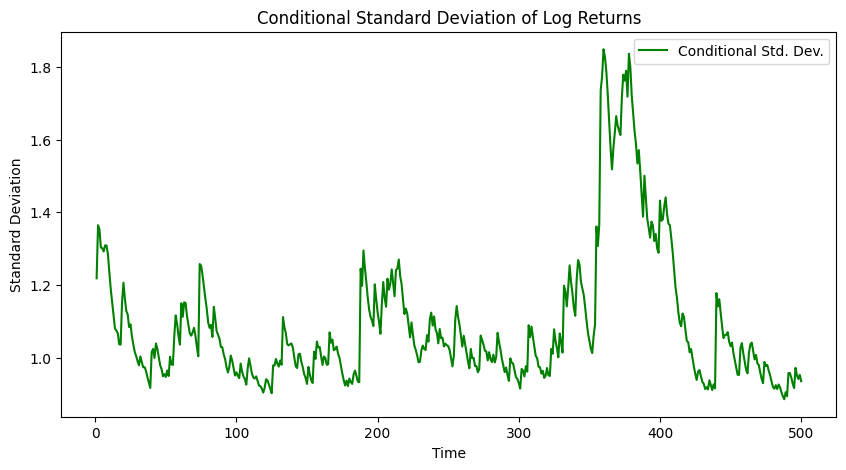

In [56]:
# Plot the conditional standard deviation of the log returns
plt.figure(figsize=(10, 5))
plt.plot(conditional_std_dev, label='Conditional Std. Dev.', color='green')
plt.title('Conditional Standard Deviation of Log Returns')
plt.xlabel('Time')
plt.ylabel('Standard Deviation')
plt.legend()
plt.show()


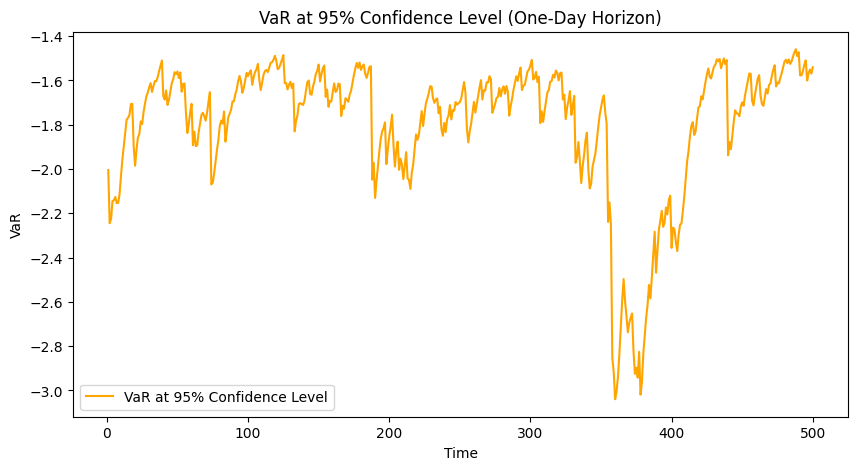

In [57]:
# 4. Estimate the VaR at 95% confidence level for a one-day horizon
confidence_level = 0.95
z_score = norm.ppf(1 - confidence_level)  # Inverse CDF of normal distribution
VaR_95 = z_score * conditional_std_dev

# Plot the VaR
plt.figure(figsize=(10, 5))
plt.plot(VaR_95, label='VaR at 95% Confidence Level', color='orange')
plt.title('VaR at 95% Confidence Level (One-Day Horizon)')
plt.xlabel('Time')
plt.ylabel('VaR')
plt.legend()
plt.show()


In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2

# 1. Evaluate the performance of the VaR estimation (Backtesting)

# Calculate violations (actual returns exceeding VaR)
violations = scaled_log_returns < VaR_95
violation_count = np.sum(violations)
total_days = len(scaled_log_returns)
hit_ratio = violation_count / total_days  # Percentage of violations


In [59]:
# Mean violation ratio
mean_violation_ratio = np.mean(scaled_log_returns[violations] / VaR_95[violations])

# Kupiec test statistic
p = 0.05  # Expected violation rate at 95% confidence level
kupiec_stat = -2 * (np.log((1 - p)**(total_days - violation_count) * p**violation_count) - 
                    np.log(((total_days - violation_count) / total_days)**(total_days - violation_count) * 
                           (violation_count / total_days)**violation_count))
kupiec_p_value = 1 - chi2.cdf(kupiec_stat, df=1)

# Print performance metrics
print(f"Total Violations: {violation_count}")
print(f"Hit Ratio: {hit_ratio:.4f} (Expected: 0.05)")
print(f"Mean Violation Ratio: {mean_violation_ratio:.4f}")
print(f"Kupiec Test Statistic: {kupiec_stat:.4f}")
print(f"Kupiec Test p-value: {kupiec_p_value:.4f}")

Total Violations: 34
Hit Ratio: 0.0680 (Expected: 0.05)
Mean Violation Ratio: 1.4791
Kupiec Test Statistic: 3.0806
Kupiec Test p-value: 0.0792


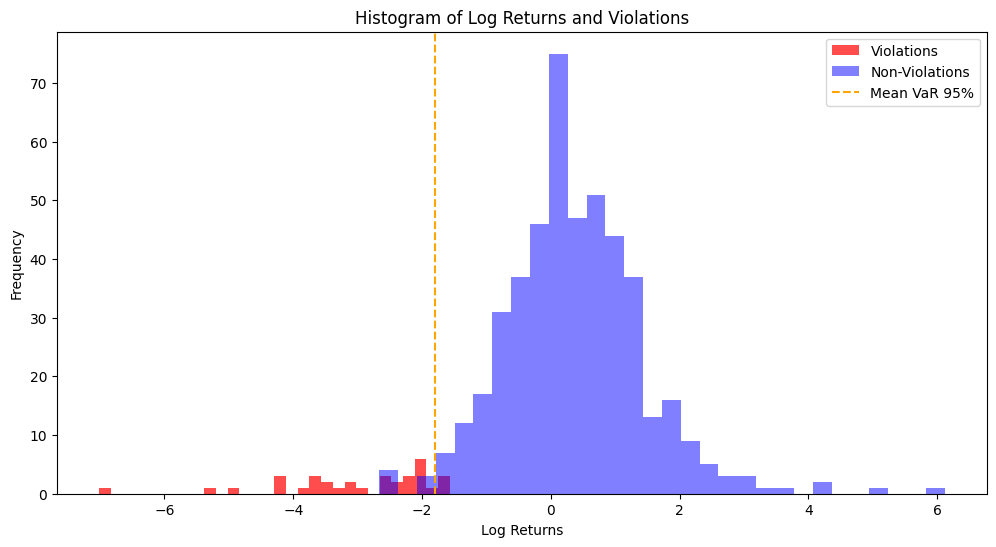

In [60]:
plt.figure(figsize=(12, 6))
plt.hist(scaled_log_returns[violations], bins=30, color='red', alpha=0.7, label='Violations')
plt.hist(scaled_log_returns[~violations], bins=30, color='blue', alpha=0.5, label='Non-Violations')
plt.axvline(x=VaR_95.mean(), color='orange', linestyle='--', label='Mean VaR 95%')
plt.title('Histogram of Log Returns and Violations')
plt.xlabel('Log Returns')
plt.ylabel('Frequency')
plt.legend()
plt.show()

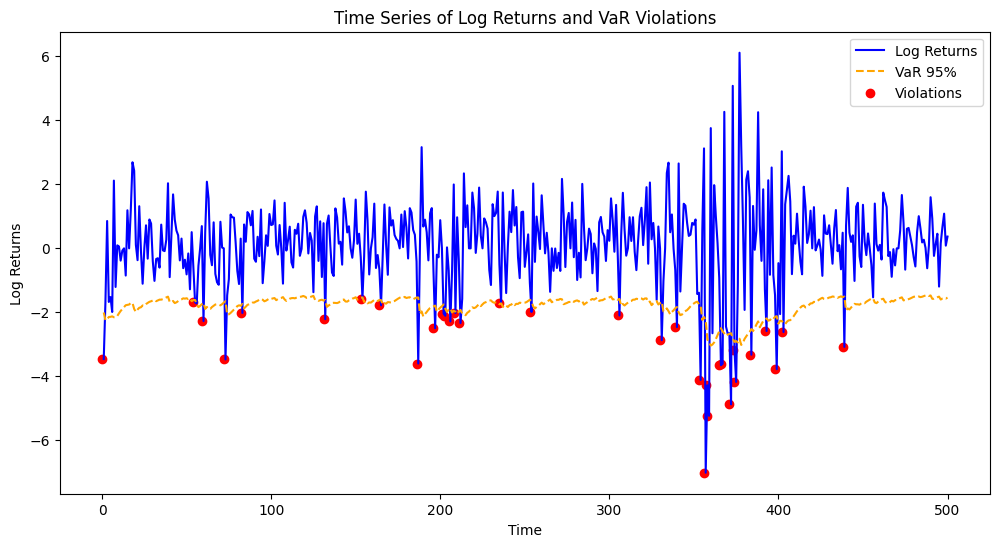

In [61]:
plt.figure(figsize=(12, 6))
plt.plot(scaled_log_returns, label='Log Returns', color='blue')
plt.plot(VaR_95, label='VaR 95%', color='orange', linestyle='--')
plt.scatter(np.where(violations)[0], scaled_log_returns[violations], color='red', label='Violations')
plt.title('Time Series of Log Returns and VaR Violations')
plt.xlabel('Time')
plt.ylabel('Log Returns')
plt.legend()
plt.show()
